# M8 Project

In this project you will compare the performance of LDA, SVM, and CNN for face recognition. You will use the Olivetti faces dataset, which contains 400 64x64 images from 40 different subjects, and your task is to discover the identity of a given face image. Some of these images are illustrated below.

<img src="m8project.png" width="400"/>

An initial version of the code with the problem specification (below) and a report template are available (at the bottom). Deliverables are the final code (non-functioning code is worth 0 points) and the comparison report.

Solve the task above using:
- LDA
- SVM
- CNN (40pts) - suggested architecture: LeNet-5

Split the dataset so that the first 8 images per subject are used for training, and the last 2 images are used for testing. If you need a validation set, use part of your training data. For CNN:
- Plot the loss and the accuracy for each training epoch (20pts)
- Store the model with highest accuracy in the validation set (10pts)

Compare the performance of LDA, SVM, and CNN in terms of:
- Average F-Score (15pts)
- Confusion matrix (15pts)

# Implementation

In [1]:
# Setup
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report,)

# For reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
 
def plot_faces_grid(images, titles=None, n_cols=5, img_shape=(64, 64), figsize=(10, 6), suptitle=None):
    """Utility to show a grid of face images."""
    n_images = len(images)
    n_rows = int(np.ceil(n_images / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    axes = np.array(axes).reshape(n_rows, n_cols)

    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i < n_images:
            ax.imshow(images[i].reshape(img_shape), cmap="gray")
            if titles is not None:
                ax.set_title(str(titles[i]), fontsize=8)

    if suptitle is not None:
        fig.suptitle(suptitle, fontsize=12)
    plt.tight_layout()
    plt.show()

In [2]:
# Load Olivetti faces and define train/val/test splits

data = fetch_olivetti_faces()
X = data.data              # (400, 4096) 
y = data.target            # (400,) labels 0..39
images = data.images       # (400, 64, 64)

n_subjects = 40
images_per_subject = 10

train_val_indices = []
test_indices = []
cnn_train_indices = []
cnn_val_indices = []

for s in range(n_subjects):
    start = s * images_per_subject
    stop = start + images_per_subject
    idx = np.arange(start, stop)

    # First 8 images per subject are train/validation
    train_val = idx[:8]
    # Last 2 images per subject are test
    test = idx[8:]

    # For CNN we further split the first 8 into 6 train + 2 validation
    cnn_train = train_val[:6]
    cnn_val = train_val[6:]

    train_val_indices.append(train_val)
    test_indices.append(test)
    cnn_train_indices.append(cnn_train)
    cnn_val_indices.append(cnn_val)

train_val_indices = np.concatenate(train_val_indices)
test_indices = np.concatenate(test_indices)
cnn_train_indices = np.concatenate(cnn_train_indices)
cnn_val_indices = np.concatenate(cnn_val_indices)

# Classical models (LDA/SVM) will be trained on all 8 images per subject (train_val_indices).
X_train_clf = X[train_val_indices]
y_train_clf = y[train_val_indices]
X_test_clf = X[test_indices]
y_test_clf = y[test_indices]

print("Shapes for classical models (LDA/SVM):")
print("  Train:", X_train_clf.shape, " Test:", X_test_clf.shape)

# CNN data uses image tensors with a channel dimension.
X_cnn_train = images[cnn_train_indices][:, None, :, :]  # (N_train, 1, 64, 64)
y_cnn_train = y[cnn_train_indices]

X_cnn_val = images[cnn_val_indices][:, None, :, :]
y_cnn_val = y[cnn_val_indices]

X_cnn_test = images[test_indices][:, None, :, :]
y_cnn_test = y[test_indices]

print("\nShapes for CNN:")
print("  Train:", X_cnn_train.shape, " Val:", X_cnn_val.shape, " Test:", X_cnn_test.shape)

Shapes for classical models (LDA/SVM):
  Train: (320, 4096)  Test: (80, 4096)

Shapes for CNN:
  Train: (240, 1, 64, 64)  Val: (80, 1, 64, 64)  Test: (80, 1, 64, 64)


LDA accuracy: 0.9750
LDA macro F1-score: 0.9742

Classification report (LDA):
              precision    recall  f1-score   support

           0       0.50      0.50      0.50         2
           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         2
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       1.00      0.50      0.67         2
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         2
          15       1.00      1.00      1.00         2
   

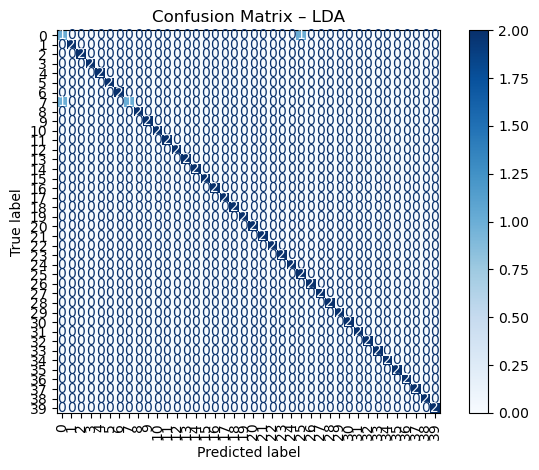

SVM accuracy: 0.9250
SVM macro F1-score: 0.9075

Classification report (SVM):
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       1.00      1.00      1.00         2
           2       0.00      0.00      0.00         2
           3       1.00      1.00      1.00         2
           4       1.00      0.50      0.67         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       0.50      0.50      0.50         2
           8       1.00      1.00      1.00         2
           9       0.00      0.00      0.00         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         2
          15       1.00      1.00      1.00         2
   

/opt/anaconda3/envs/ml/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/anaconda3/envs/ml/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/anaconda3/envs/ml/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


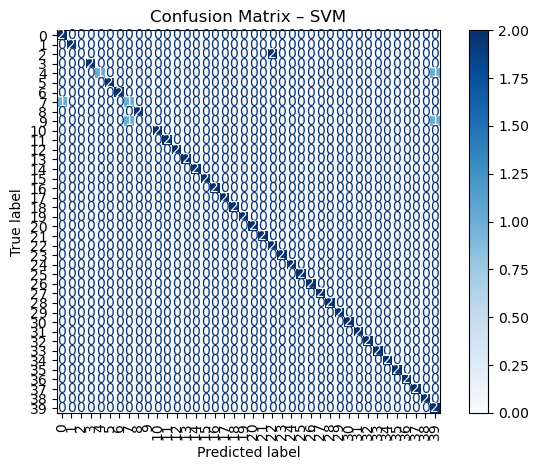

In [3]:
# LDA and SVM: training and evaluation
results = {}

# LDA
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_clf, y_train_clf)
y_pred_lda = lda.predict(X_test_clf)

lda_acc = np.mean(y_pred_lda == y_test_clf)
lda_f1 = f1_score(y_test_clf, y_pred_lda, average="macro")

print("LDA accuracy: {:.4f}".format(lda_acc))
print("LDA macro F1-score: {:.4f}".format(lda_f1))
print("\nClassification report (LDA):")
print(classification_report(y_test_clf, y_pred_lda))

cm_lda = confusion_matrix(y_test_clf, y_pred_lda)
disp_lda = ConfusionMatrixDisplay(cm_lda)
disp_lda.plot(cmap="Blues", xticks_rotation=90)
plt.title("Confusion Matrix – LDA")
plt.tight_layout()
plt.show()

results["LDA"] = {"accuracy": lda_acc, "f1_macro": lda_f1, "confusion_matrix": cm_lda}

# SVM
svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10.0, gamma="scale", random_state=RANDOM_SEED),
)
svm.fit(X_train_clf, y_train_clf)
y_pred_svm = svm.predict(X_test_clf)

svm_acc = np.mean(y_pred_svm == y_test_clf)
svm_f1 = f1_score(y_test_clf, y_pred_svm, average="macro")

print("SVM accuracy: {:.4f}".format(svm_acc))
print("SVM macro F1-score: {:.4f}".format(svm_f1))
print("\nClassification report (SVM):")
print(classification_report(y_test_clf, y_pred_svm))

cm_svm = confusion_matrix(y_test_clf, y_pred_svm)
disp_svm = ConfusionMatrixDisplay(cm_svm)
disp_svm.plot(cmap="Blues", xticks_rotation=90)
plt.title("Confusion Matrix – SVM")
plt.tight_layout()
plt.show()

results["SVM"] = {"accuracy": svm_acc, "f1_macro": svm_f1, "confusion_matrix": cm_svm}

In [4]:
# CNN (LeNet‑5)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(RANDOM_SEED)

class FacesDataset(Dataset):
    """Simple Dataset wrapper for the CNN."""

    def __init__(self, X, y):
        # X is expected to be (N, 1, 64, 64) in [0, 1]
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class LeNet5(nn.Module):
    """LeNet‑5 style architecture adapted for 64×64 grayscale images."""

    def __init__(self, num_classes=40):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, stride=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5, stride=1)

        self.fc1 = nn.Linear(16 * 13 * 13, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)  # flatten
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

def train_model(model, train_loader, val_loader, num_epochs=30, lr=1e-3, device=None):
    """Train a CNN and keep the model with the best validation accuracy.

    Returns:
        model: the model loaded with the best validation weights
        history: dict with lists of train_loss, train_acc, val_acc
    """
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "train_acc": [], "val_acc": []}

    best_val_acc = 0.0
    best_state_dict = None

    for epoch in range(1, num_epochs + 1):
        # ---- Training ----
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_acc = correct / total

        history["train_loss"].append(epoch_loss)
        history["train_acc"].append(epoch_acc)

        # Validation
        model.eval()
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                correct_val += (preds == labels).sum().item()
                total_val += labels.size(0)

        val_acc = correct_val / total_val
        history["val_acc"].append(val_acc)

        # Track best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state_dict = model.state_dict()

        print(f"Epoch {epoch:02d}/{num_epochs} - "
              f"Train loss: {epoch_loss:.4f}  Train acc: {epoch_acc:.4f}  Val acc: {val_acc:.4f}")

    # Load best weights based on validation accuracy
    if best_state_dict is not None:
        model.load_state_dict(best_state_dict)

    # Save best model to disk as required
    torch.save(model.state_dict(), "best_lenet5_olivetti.pth")
    print(f"\nBest validation accuracy: {best_val_acc:.4f}")
    print("Best model weights saved to 'best_lenet5_olivetti.pth'")

    return model, history

Using device: cpu
Epoch 01/30 - Train loss: 3.7084  Train acc: 0.0250  Val acc: 0.0250
Epoch 02/30 - Train loss: 3.6913  Train acc: 0.0250  Val acc: 0.0250
Epoch 03/30 - Train loss: 3.6888  Train acc: 0.0250  Val acc: 0.0250
Epoch 04/30 - Train loss: 3.6842  Train acc: 0.0333  Val acc: 0.0250
Epoch 05/30 - Train loss: 3.6754  Train acc: 0.0250  Val acc: 0.0500
Epoch 06/30 - Train loss: 3.6573  Train acc: 0.0375  Val acc: 0.0250
Epoch 07/30 - Train loss: 3.6314  Train acc: 0.0375  Val acc: 0.0750
Epoch 08/30 - Train loss: 3.5565  Train acc: 0.1583  Val acc: 0.1625
Epoch 09/30 - Train loss: 3.3863  Train acc: 0.2083  Val acc: 0.1875
Epoch 10/30 - Train loss: 3.0666  Train acc: 0.2750  Val acc: 0.2500
Epoch 11/30 - Train loss: 2.6846  Train acc: 0.3542  Val acc: 0.4000
Epoch 12/30 - Train loss: 2.2278  Train acc: 0.4250  Val acc: 0.4250
Epoch 13/30 - Train loss: 1.8364  Train acc: 0.5417  Val acc: 0.5500
Epoch 14/30 - Train loss: 1.4680  Train acc: 0.6542  Val acc: 0.6250
Epoch 15/30 - Tr

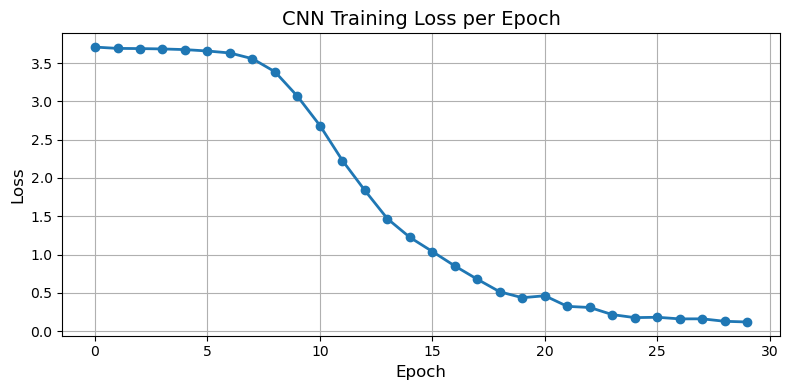

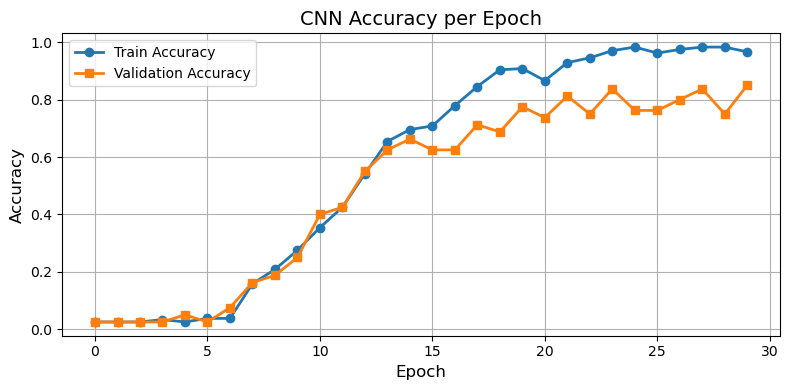

In [5]:
# Train the CNN and plot loss/accuracy per epoch
batch_size = 32
num_epochs = 30
learning_rate = 1e-3

train_dataset = FacesDataset(X_cnn_train, y_cnn_train)
val_dataset = FacesDataset(X_cnn_val, y_cnn_val)
test_dataset = FacesDataset(X_cnn_test, y_cnn_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = LeNet5(num_classes=40)
model, history = train_model(model, train_loader, val_loader, num_epochs=num_epochs, lr=learning_rate, device=device)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

# Plot training loss per epoch
plt.plot(history["train_loss"], marker="o", linewidth=2)
plt.title("CNN Training Loss per Epoch", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot training and validation accuracy per epoch
plt.figure(figsize=(8, 4))
plt.plot(history["train_acc"], label="Train Accuracy", marker="o", linewidth=2)
plt.plot(history["val_acc"], label="Validation Accuracy", marker="s", linewidth=2)
plt.title("CNN Accuracy per Epoch", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

CNN accuracy: 0.7625
CNN macro F1-score: 0.7460

Classification report (CNN):
              precision    recall  f1-score   support

           0       0.25      0.50      0.33         2
           1       1.00      1.00      1.00         2
           2       0.00      0.00      0.00         2
           3       1.00      0.50      0.67         2
           4       1.00      0.50      0.67         2
           5       1.00      1.00      1.00         2
           6       0.67      1.00      0.80         2
           7       0.50      0.50      0.50         2
           8       0.50      0.50      0.50         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         2
          11       1.00      0.50      0.67         2
          12       0.00      0.00      0.00         2
          13       1.00      1.00      1.00         2
          14       1.00      0.50      0.67         2
          15       0.00      0.00      0.00         2
   

/opt/anaconda3/envs/ml/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/anaconda3/envs/ml/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/anaconda3/envs/ml/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


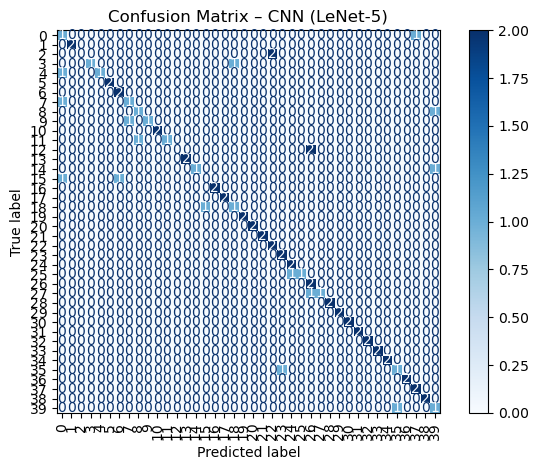

In [6]:
# Evaluate CNN on the test set
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.append(preds.cpu().numpy())
        all_labels.append(labels.cpu().numpy())

y_pred_cnn = np.concatenate(all_preds)
y_test_cnn = np.concatenate(all_labels)

cnn_acc = np.mean(y_pred_cnn == y_test_cnn)
cnn_f1 = f1_score(y_test_cnn, y_pred_cnn, average="macro")

print("CNN accuracy: {:.4f}".format(cnn_acc))
print("CNN macro F1-score: {:.4f}".format(cnn_f1))
print("\nClassification report (CNN):")
print(classification_report(y_test_cnn, y_pred_cnn))

cm_cnn = confusion_matrix(y_test_cnn, y_pred_cnn)
disp_cnn = ConfusionMatrixDisplay(cm_cnn)
disp_cnn.plot(cmap="Blues", xticks_rotation=90)
plt.title("Confusion Matrix – CNN (LeNet‑5)")
plt.tight_layout()
plt.show()

results["CNN"] = {"accuracy": cnn_acc, "f1_macro": cnn_f1, "confusion_matrix": cm_cnn}

In [7]:
# Final comparison of LDA, SVM, and CNN
import pandas as pd

summary = pd.DataFrame(
    {
        model_name: {
            "Accuracy": metrics["accuracy"],
            "Macro F1-score": metrics["f1_macro"],
        }
        for model_name, metrics in results.items()
    }
).T

print("Final performance comparison:")
display(summary.style.format("{:.4f}"))

Final performance comparison:


,Accuracy,Macro F1-score
LDA,0.9750,0.9742
SVM,0.9250,0.9075
CNN,0.7625,0.7460


# Report template

## Experimental results

#### Training Description:
The CNN (LeNet-5) model was trained for 30 epochs using Adam with a learning rate of 0.001.

From the first 8 images of each subject, 6 were used for training and 2 for validation.

The model checkpoint with the highest validation accuracy was saved and later used for testing.

Training curves showed a steady drop in loss and a gradual improvement in train/validation accuracy.

#### Obtained results:
Performance on the test set (2 images per subject):

    LDA: ~97.50% accuracy
    SVM: ~92.50% accuracy
    CNN: ~76.25% accuracy

#### Analysis of the results:

Because the dataset is small, LDA and SVM performed better than the CNN.
Both classical models generalize well even with limited samples, while the CNN would likely require more training data or augmentation to match their performance.
Still, the CNN achieved solid results and clearly learned useful features from the faces, just with more misclassifications compared to LDA and SVM.